In [2]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import scipy as sp
import mplhep as hep
plt.style.use(hep.style.CMS)
import awkward1 as ak
import pandas as pd
from scipy import stats
from shapely.geometry import box
from shapely.ops import unary_union
import os, sys
import matplotlib.ticker as ticker
import bisect
import math
import random

may have to expand range of masses we're considering below

In [3]:
with open("/spinquest/analysis/yields/BremYield.txt", "r") as brem_file:
    brem_yield_lines = brem_file.read().splitlines()

# for DP trigger
brem_yield_lines = brem_yield_lines[119:170] # range of masses we need for DP trigger, nonzero events end result # 119 : 200 for both
for i in range(len(brem_yield_lines)):
    brem_yield_lines[i] = [float(num) for num in brem_yield_lines[i].split()]

brem_yield_dict = dict(brem_yield_lines) # dictionary with keys = log(mass), values = log(N_prod)

# we interpolate more values near the 0.77 GeV mass where we have sensitivity

log_xvals = list(brem_yield_dict.keys())
log_yvals = list(brem_yield_dict.values())

logxval_interp = np.linspace(log_xvals[27], log_xvals[28], 11)[1:].tolist() + np.linspace(log_xvals[28], log_xvals[29], 12)[1:-1].tolist()
# start with 27, end on 28, put 11 points there including 27 and 28, then remove 27
# start with 28, end on 29, put 12 points there including 28 and 29, then remove 28 and 29
logyval_interp = np.interp(logxval_interp, log_xvals, log_yvals).tolist()

log_xnew = log_xvals[:28] + logxval_interp + log_xvals[28:]
log_ynew = log_yvals[:28] + logyval_interp + log_yvals[28:]

brem_yield_lines = [list(pair) for pair in zip(log_xnew, log_ynew)]


get PoT per run

In [4]:
pot_df = pd.read_csv("/home/mtian7/DarkQuest/e1039-analysis/python/per_run_corrected_PoT.tsv", sep = "\t")
pot_list = pot_df["PoT_corrected"].to_list()

with open("/home/mtian7/DarkQuest/e1039-analysis/python/prescale_values.txt", "r") as prescale_file:
    prescale_lists = [[float(num) for num in line.split()] for line in prescale_file]

# reorder to match MC: nim 1, 2, 3, 4, fpga 1, 2, 3, 4
# data has: nim 1, 2, 3, 4, fpga 1, 2, 3, 4, 5
for i in range(len(prescale_lists)):
    prescale_lists[i] = [prescale_lists[i][0], prescale_lists[i][1], prescale_lists[i][2], prescale_lists[i][8], prescale_lists[i][4], prescale_lists[i][5], prescale_lists[i][6], prescale_lists[i][7]]

In [5]:
avg_prescale_list = [None] * 8

for i in range(8): # nim 4, which is index 3 in my list, has to be calculated differently
    total = 0 # prescale = total events / events saved
    saved = 0
    subtotal = 0

    for j in range(len(pot_list)):
        total += pot_list[j]
        if i == 3: # nim 4
            if (j >= 61 and j <= 67): # if DP trigger (MC nim 4), and one of the 6 runs where it is on
                saved += pot_list[j] / prescale_lists[j][i]
                subtotal += pot_list[j]
            else:
                saved += 0
        else:
            saved += pot_list[j] / prescale_lists[j][i]

    avg_prescale_list[i] = total / saved
avg_prescale_list

[70.42425307664155,
 692.0910441476154,
 7.0611867482585895,
 286.52530243018174,
 1.0,
 4.400652415165355,
 4.400652415165355,
 550.1242211746036]

In [ ]:
def getData(df):
    # needed this for eta this is not doing anything now
    df = df[df["n_truthdimuons"] != 0]

    df["a_prime_pz"] = df["truthdimuon_pz"].apply(lambda x: x[-1]) # last one in the list is the one corresponding to the dark photon
    df["a_prime_zvtx"] = df["truthdimuon_z_vtx"].apply(lambda x: x[-1]) # last one in the list is the one corresponding to the dark photon

    # MC mapping for triggers below

    df["any_nim"] = df["nim_trigger"].map(any).astype(int) # 1 if any nim trigger is fired, otherwise 0
    df["any_fpga"] = df["fpga_trigger"].map(any).astype(int) # 1 if any fpga trigger is fired, otherwise 0

    df["any_trigger"] = df["any_nim"] | df["any_fpga"]
    # ^ we use this for combined trigger efficiency, no prescale

    # these are the probabilities that the trigger does NOT save the event
    # do not use these as trigger efficiencies individually!! still have to subtract from 1
    df["nim_1"] = df["nim_trigger"].apply(lambda x: 1 if int(bool(x[0])) == 0 else (1 - 1/avg_prescale_list[0]))
    df["nim_2"] = df["nim_trigger"].apply(lambda x: 1 if int(bool(x[1])) == 0 else (1 - 1/avg_prescale_list[1]))
    df["nim_3"] = df["nim_trigger"].apply(lambda x: 1 if int(bool(x[2])) == 0 else (1 - 1/avg_prescale_list[2]))
    df["nim_4"] = df["nim_trigger"].apply(lambda x: 1 if int(bool(x[3])) == 0 else (1 - 1/avg_prescale_list[3]))

    df["fpga_1"] = df["fpga_trigger"].apply(lambda x: 1 if int(bool(x[0])) == 0 else (1 - 1/avg_prescale_list[4]))
    df["fpga_2"] = df["fpga_trigger"].apply(lambda x: 1 if int(bool(x[1])) == 0 else (1 - 1/avg_prescale_list[5]))
    df["fpga_3"] = df["fpga_trigger"].apply(lambda x: 1 if int(bool(x[2])) == 0 else (1 - 1/avg_prescale_list[6]))
    df["fpga_4"] = df["fpga_trigger"].apply(lambda x: 1 if int(bool(x[3])) == 0 else (1 - 1/avg_prescale_list[7]))

    # 1 - probability that none of the triggers save the event = probability that at least 1 trigger saves it
    df["prescale_weight"] = 1 - (df["nim_1"] * df["nim_2"] * df["nim_3"] * df["nim_4"] * df["fpga_1"] * df["fpga_2"] * df["fpga_3"] * df["fpga_4"])

    # df["a_prime_recoed"] = df["truthdimuon_recoed"].apply(lambda x: x[-1]) # last one in the list is the one corresponding to the dark photon
    df["a_prime_recoed"] = df["mainDMRecoed"]
    # ^ the first analysis cut = reconstruction efficiency

    # analysis cuts
    df["d_hits"] = df["n_hits_d0x"] + df["n_hits_d2x"] + df["n_hits_d3px"] + df["n_hits_d3mx"]
    df["d_selection"] = df["d_hits"].apply(lambda x: (x > 5) & (x < 9))

    df["h_hits"] = df["n_hits_h1x"] + df["n_hits_h2x"] + df["n_hits_h3x"] + df["n_hits_h4x"]
    df["h_selection"] = df["h_hits"].apply(lambda x: (x > 7) & (x < 16))

    # df["pmom_selection"] = df["dimuon_pmom_z"].apply(lambda x: x[-1] < 22 if len(x) > 0 else False) # do not pass the cut if there's no reco DP
    # df["nmom_selection"] = df["dimuon_nmom_z"].apply(lambda x: x[-1] < 22 if len(x) > 0 else False) # may be changed to 22? unclear
    # df["pz_selection"] = df["pmom_selection"] & df["nmom_selection"]

    df["chisq_selection"] = df["dimuon_chisq_vx"].apply(lambda x: x[-1] < 20 if len(x) > 0 else False)
    df["z_selection"] = df["dimuon_z_vtx"].apply(lambda x: x[-1] > 500 if len(x) > 0 else False)

    # remove pz_selection, and cut on dimuon mass between 0.5 and 0.9 GeV

    df["selection_efficiency"] = df["d_selection"] & df["h_selection"] & df["chisq_selection"] & df["z_selection"]
    # df["selection_efficiency"] = 1

    return df

In [ ]:
brem_file_m0pt25_e6 = uproot.open("/home/mtian7/DarkQuest/e1039-analysis/SimHits/macro/Brem_0.250000_z500_600_eps_-6.root")
brem_df_m0pt25_e6 = getData(brem_file_m0pt25_e6["Events"].arrays(library = "pd"))

brem_file_m0pt45_e6 = uproot.open("/home/mtian7/DarkQuest/e1039-analysis/SimHits/macro/Brem_0.450000_z500_600_eps_-6.root")
brem_df_m0pt45_e6 = getData(brem_file_m0pt45_e6["Events"].arrays(library = "pd"))

brem_file_m0pt65_e6 = uproot.open("/home/mtian7/DarkQuest/e1039-analysis/SimHits/macro/Brem_0.650000_z500_600_eps_-6.root")
brem_df_m0pt65_e6 = getData(brem_file_m0pt65_e6["Events"].arrays(library = "pd"))

brem_file_m0pt85_e6 = uproot.open("/home/mtian7/DarkQuest/e1039-analysis/SimHits/macro/Brem_0.850000_z500_600_eps_-6.root")
brem_df_m0pt85_e6 = getData(brem_file_m0pt85_e6["Events"].arrays(library = "pd"))

brem_file_m1pt05_e6 = uproot.open("/home/mtian7/DarkQuest/e1039-analysis/SimHits/macro/Brem_1.050000_z500_600_eps_-6.root")
brem_df_m1pt05_e6 = getData(brem_file_m1pt05_e6["Events"].arrays(library = "pd"))

brem_file_m1pt25_e6 = uproot.open("/home/mtian7/DarkQuest/e1039-analysis/SimHits/macro/Brem_1.250000_z500_600_eps_-6.root")
brem_df_m1pt25_e6 = getData(brem_file_m1pt25_e6["Events"].arrays(library = "pd"))

brem_df_dict = {
        0.25: brem_df_m0pt25_e6,
        0.45: brem_df_m0pt45_e6,
        0.65: brem_df_m0pt65_e6,
        0.85: brem_df_m0pt85_e6,
        1.05: brem_df_m1pt05_e6,
        1.25: brem_df_m1pt25_e6,
        }

In [134]:
eps_0 = 10**(-6) # from BremYield.txt

In [135]:
brem_masses_list, brem_N_prod_list = [], [] # list of everything in BremYield.txt
for line in brem_yield_lines:
    brem_masses_list.append(10**line[0])
    brem_N_prod_list.append(10**line[1])

brem_N_prod_dict = dict(zip(brem_masses_list, brem_N_prod_list)) # dictionary with keys = mass, values = N_prod

In [ ]:
def calc_efficiency_lists(df): # calculates for each of the pz bins, returns bin center + value, do tree stuff later

    # for trigger efficiency
    xValues = df["a_prime_pz"].to_list() # values corresponding to the dark photon with decay in the right region 
    yValues = df["a_prime_zvtx"].to_list() # these are both truth values so taking [-1] is valid, will give full 10k events for brem

    trigger_stats = df["any_trigger"].to_list() # combined trigger efficiency, no prescale / just 1 for each event
    prescale_weight = df["prescale_weight"].to_list() # prescale weight for each event
    reco_stats = df["a_prime_recoed"].to_list() # reconstruction requirement
    selection_stats = df["selection_efficiency"].to_list() # whether the important dimuon passed all selection cuts, 1 or 0

    total_stats = [a * b * c * d for a, b, c, d in zip(trigger_stats, prescale_weight, reco_stats, selection_stats)]

    pzedges = np.percentile(xValues, [i for i in range(0, 101, 20)])
    zedges = np.percentile(yValues, [i for i in range(0, 101, 20)])

    bin_means, bin_xedges, bin_yedges, bin_num = stats.binned_statistic_2d(xValues, yValues, total_stats, statistic = "mean", bins = [pzedges, zedges])
    bin_xcenters = (bin_xedges[:-1] + bin_xedges[1:]) / 2
    bin_ycenters = (bin_yedges[:-1] + bin_yedges[1:]) / 2

    reco_info = bin_xcenters, bin_ycenters, bin_means # this is reco efficiency with trigger & selection cuts. for just trigger, leave reco_stats out of multiplication

    return reco_info

In [ ]:
# copied from online it probably works
def find_closest(array, target):
    # Find the insertion point
    idx = bisect.bisect_left(array, target)
    
    # If target is smaller than everything
    if idx == 0:
        return array[0]
    # If target is larger than everything
    if idx == len(array):
        return array[-1]
    
    # Check which of the two neighboring values is closer
    before = array[idx - 1]
    after = array[idx]
    if abs(after - target) < abs(before - target):
        return after
    return before

In [ ]:
def get_closest_value(x, y, xcenters, ycenters, array): # non empty
    x_grid, y_grid = np.meshgrid(xcenters, ycenters, indexing = "ij") # turns into 2D grid
    nonempty_mask = ~np.isnan(array) # array is bin means

    nonempty_xcenters = x_grid[nonempty_mask]
    nonempty_ycenters = y_grid[nonempty_mask]
    nonempty_means = array[nonempty_mask]

    distances = np.hypot(nonempty_xcenters - x, nonempty_ycenters - y)
    closest_idx = np.argmin(distances)

    return nonempty_means[closest_idx]

In [140]:
def get_proper_lifetime(eps, mass):
    alpha = 0.0072973525643 # 1/137
    m_mu = 0.1056583755 # muon mass GeV
    decay_width = (alpha * eps**2 * mass)/3 * (1 + (2 * (m_mu**2)/mass**2)) * np.sqrt(1 - (4 * (m_mu**2)/mass**2))
    hbar = 6.582119569 * (10**(-25)) #GeV*s
    return hbar/decay_width
    # should be in seconds now

# done for each individual event based on pz, take average afterward
def get_P_decay(pz, eps, mass):
    c = 299792458 # m/s, to convert mass/pz in GeV/GeV back to seconds/meter
    tau = get_proper_lifetime(eps, mass) # in seconds
    return np.exp(-5 * mass/pz * 1/c * 1/tau * (eps**2) / (eps_0**2)) - np.exp(-6 * mass/pz * 1/c * 1/tau * (eps**2) / (eps_0**2)) # between z1 at 500cm and z2 at 600cm

def get_P_decay_avg(df, eps, mass):
    # for some df, average over all pz
    pz_values = np.array(df["a_prime_pz"])
    P_decay_values = get_P_decay(pz_values, eps, mass)
    return np.mean(P_decay_values)


In [141]:
brem_efficiency_lists = []
for i in brem_df_dict:
    brem_efficiency_lists.append(calc_efficiency_lists(brem_df_dict[i]))

brem_efficiency_dict = dict(zip(list(brem_df_dict), brem_efficiency_lists))


In [ ]:
def get_N_signal_brem(mass, eps, POT):
    # get the relevant df based on mass
    brem_df_masses = list(brem_df_dict.keys()) # list of masses we have data for
    brem_closest_df_mass = find_closest(brem_df_masses, mass) # closest mass we have data for, number
    df_calc = brem_df_dict[brem_closest_df_mass] # get the df for that mass

    efficiency_output = brem_efficiency_dict[brem_closest_df_mass] # get the efficiency dictionaries for that mass

    reco_x, reco_y, reco_stats = efficiency_output

    factors = [] # efficiency * P_decay

    df_pz_list = df_calc["a_prime_pz"].to_list()
    df_zvtx_list = df_calc["a_prime_zvtx"].to_list()
    random_indices = random.sample(range(0, len(df_pz_list)), len(df_pz_list)) # fiddle w this value

    for i in random_indices:
        pz = df_pz_list[i]
        zvtx = df_zvtx_list[i]
        P_decay = get_P_decay(pz, eps, mass)
        closest_reco_value = get_closest_value(pz, zvtx, reco_x, reco_y, reco_stats)
        factors.append(closest_reco_value * P_decay)
    
    # get the relevant N_prod based on mass
    N_prod = brem_N_prod_dict[mass] * POT / (1.44 * (10**18)) # scale by POT

    return N_prod * (eps/eps_0)**2 * np.nanmean(factors)

In [ ]:
def find_intersection_x(x, c, y2):
    # where x and y2 are lists, and c is a number
    y1 = []
    for xval in x: 
        y1.append(c)
    x = np.array(x)
    y1 = np.array(y1)
    y2 = np.array(y2)

    index = np.argwhere(np.diff(np.sign(y2-y1))).flatten()
    x_intersections = []

    for i in index:
        x_int = x[i] + (x[i+1] - x[i])*(np.abs(y1[i] - y2[i]))/(np.abs(y2[i+1]-y1[i+1]) + np.abs(y1[i]-y2[i]))
        x_intersections.append(x_int)
    
    return x_intersections

In [ ]:
exp = np.linspace(-5, -7, 65) # 2^6 + 1? for convenience in the grid plot later on
x = 10**exp # the actual epsilon
mylist = []
for xvar in x:
    mylist.append(get_N_signal_brem(brem_masses_list[36], xvar, 1.835*(10**15)))
mylist
# just to see what values look like for 0.77 GeV mass which is where the best N_prod is

[np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(1.3171105306469187e-247),
 np.float64(4.713048693943076e-186),
 np.float64(6.693829294615427e-140),
 np.float64(2.7128581290590063e-105),
 np.float64(2.4472337756619615e-79),
 np.float64(7.242898315108094e-60),
 np.float64(2.9711530782286185e-45),
 np.float64(2.789820013749165e-34),
 np.float64(4.8807906962413546e-26),
 np.float64(7.625685330211525e-20),
 np.float64(3.442096543007033e-15),
 np.float64(1.0837995542282341e-11),
 np.float64(4.6108362141296666e-09),
 np.float64(4.3441544210167877e-07),
 np.float64(1.3149530301143102e-05),
 np.float64(0.0001723294035915635),
 np.float64(0.0012761780688606806),
 np.float64(0.006593981836994034),
 np.float64(0.025912542636476688),
 np.float64(0.07743673088445026),
 np.float64(0.17664851278997296),
 np.float64(0.3164185277697056),
 np.float64(0.46223091607342875),
 np.float64(0.571104287518

In [146]:
exp = np.linspace(-5, -7, 65) # 2^6 + 1? for convenience in the grid plot later on
x = 10**exp # the actual epsilon

brem_output_list_15 = []
for brem_mass in brem_masses_list:
    brem_y = []
    for xvar in x:
        brem_y.append(get_N_signal_brem(brem_mass, xvar, 1.835*(10**15)))
    brem_output_list_15.append(brem_y)

brem_output_list_16 = []
brem_output_list_17 = [] 
brem_output_list_18 = [] # 1.44 * 10 ** 18

for i in brem_output_list_15:
    brem_output_list_16.append([j * 10 / 1.835 for j in i])
    brem_output_list_17.append([j * 100 / 1.835 for j in i])
    brem_output_list_18.append([j * 1000 * 1.44 / 1.835 for j in i])

In [148]:
brem_output_dict_15 = dict(zip(brem_masses_list, brem_output_list_15))

brem_output_dict_16 = dict(zip(brem_masses_list, brem_output_list_16))

brem_output_dict_17 = dict(zip(brem_masses_list, brem_output_list_17))

brem_output_dict_18 = dict(zip(brem_masses_list, brem_output_list_18)) # dictionary with keys = mass, values = list of N_signal for each epsilon for that mass

In [149]:
current_limits_x = []
current_limits_y = []

with open("/home/mtian7/DarkQuest/e1039-analysis/python/current_limits.txt", "r") as current_limits_file:
    for line in current_limits_file:
        current_limits_lines = line.strip().split(", ")

        current_limits_x.append(float(current_limits_lines[0]))
        current_limits_y.append(float(current_limits_lines[1]))

current_limits_x

# for i in range(len(current_limits_lines)):
#     current_limits_lines[i] = [float(num) for num in current_limits_lines[i].split()]

# current_limits_x, current_limits_y = map(list, zip(*current_limits_lines))

[0.1309058528116378,
 0.14002282338513508,
 0.1518051655297261,
 0.16237767391887242,
 0.17136342300342128,
 0.1808464306375093,
 0.1808464306375093,
 0.1808464306375093,
 0.16907141034735834,
 0.16237767391887242,
 0.1477714868970752,
 0.1309058528116378,
 0.1175372265130638,
 0.10272967317129356,
 0.09475632026539926,
 0.08623280529014948,
 0.07742636826811286,
 0.06858944835078218,
 0.06158482110660273,
 0.05604514688244569,
 0.0523960135300265,
 0.05680492161728434,
 0.062419694306676626,
 0.06858944835078218,
 0.07436096708208832,
 0.08394147730457908,
 0.09604088212505399,
 0.10841458689358371,
 0.11913061720030642,
 0.13447915475548972,
 0.1518051655297261,
 0.17136342300342128,
 0.18830150935310147,
 0.20414630347954743,
 0.22736580356831285,
 0.24983933698814662,
 0.274534223383872,
 0.2936542274344944,
 0.30990463391994333,
 0.3183640175686512,
 0.3183640175686512,
 0.35457458424656085,
 0.3844105707405505,
 0.4339372182160708,
 0.47682890387256677,
 0.5169520863226451,
 0.56

In [150]:
brem_masses_list.sort()
brem_masses_list


[0.21521318849666254,
 0.225276391461428,
 0.23581014204744974,
 0.2468364426991424,
 0.25837832467827904,
 0.27045989617069666,
 0.2831063926424371,
 0.29634422955050194,
 0.3102010575183193,
 0.32470582009117677,
 0.33988881419225064,
 0.35578175340551377,
 0.3724178342177051,
 0.3898318053577184,
 0.4080600403782521,
 0.4271406136313194,
 0.44711337979631255,
 0.4680200571267413,
 0.4899043145895247,
 0.5128118630788454,
 0.5367905508950985,
 0.5618904636883585,
 0.588164029075127,
 0.6156661261468825,
 0.6444542000991582,
 0.6745883822205937,
 0.7061316154925821,
 0.7391497860618528,
 0.7425353524472713,
 0.7459364259192997,
 0.7493530775058569,
 0.7527853785601948,
 0.7562334007623884,
 0.7596972161208327,
 0.7631768969737466,
 0.7666725159906831,
 0.7701841461740476,
 0.7737118608606226,
 0.7737118608606226,
 0.7769328938259088,
 0.7801673362448797,
 0.7834152439423125,
 0.7866766729753882,
 0.7899516796346592,
 0.7932403204450199,
 0.7965426521666839,
 0.7998587317961617,
 0.803

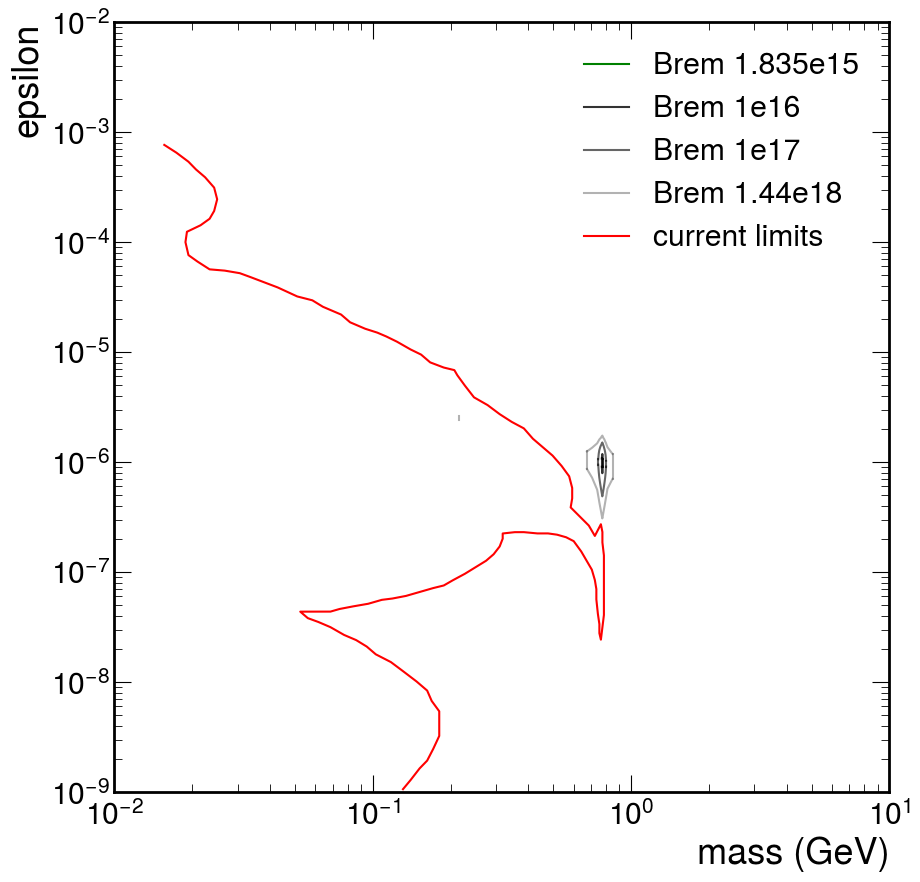

In [151]:
x = 10**np.linspace(-5, -7, 65)

brem_crossing_1 = [[], [], [], []]
brem_crossing_2 = [[], [], [], []]

brem_masses = brem_masses_list # dictionary keys, masses from yield file
for brem_mass in brem_masses:
    y = [brem_output_dict_15[brem_mass], brem_output_dict_16[brem_mass], brem_output_dict_17[brem_mass], brem_output_dict_18[brem_mass]]
    for i in range(4):
        crossings = find_intersection_x(x, 3.1, y[i]) # was 3.1
        if len(crossings) == 2:
            brem_crossing_1[i].append(crossings[0])
            brem_crossing_2[i].append(crossings[1])
        elif len(crossings) == 1:
            brem_crossing_1[i].append(crossings[0])
            brem_crossing_2[i].append(np.nan) # if only one crossing, set the second to NaN
        else:
            brem_crossing_1[i].append(np.nan)
            brem_crossing_2[i].append(np.nan) # if no crossings, set both to NaN

# now make the x values the mass, and the y values crossing_1 and crossing_2
brem_y1_15 = np.array(brem_crossing_1[0])
brem_y2_15 = np.array(brem_crossing_2[0])
brem_y1_16 = np.array(brem_crossing_1[1])
brem_y2_16 = np.array(brem_crossing_2[1])
brem_y1_17 = np.array(brem_crossing_1[2])
brem_y2_17 = np.array(brem_crossing_2[2])
brem_y1_18 = np.array(brem_crossing_1[3])
brem_y2_18 = np.array(brem_crossing_2[3])

fig, ax = plt.subplots()
ax.plot(brem_masses, brem_y1_15, color = "green", label = "Brem 1.835e15")
ax.plot(brem_masses, brem_y2_15, color = "green")
ax.plot(brem_masses, brem_y1_16, color = "black", alpha = 0.8, label = "Brem 1e16")
ax.plot(brem_masses, brem_y2_16, color = "black", alpha = 0.8)
ax.plot(brem_masses, brem_y1_17, color = "black", alpha = 0.6, label = "Brem 1e17")
ax.plot(brem_masses, brem_y2_17, color = "black", alpha = 0.6)
ax.plot(brem_masses, brem_y1_18, color = "black", alpha = 0.3, label = "Brem 1.44e18")
ax.plot(brem_masses, brem_y2_18, color = "black", alpha = 0.3)

for index, yval in enumerate(brem_y1_15):
    if (index == 0) | (index == len(brem_y1_15)-1):
        if (not math.isnan(yval)):
            ax.plot([brem_masses[index], brem_masses[index]], [brem_y1_15[index], brem_y2_15[index]], color = "green")
    elif (math.isnan(brem_y1_15[index+1])) | (math.isnan(brem_y1_15[index-1])):
        if (not math.isnan(yval)):
            ax.plot([brem_masses[index], brem_masses[index]], [brem_y1_15[index], brem_y2_15[index]], color = "green")

for index, yval in enumerate(brem_y1_16):
    if (index == 0) | (index == len(brem_y1_16)-1):
        if (not math.isnan(yval)):
            ax.plot([brem_masses[index], brem_masses[index]], [brem_y1_16[index], brem_y2_16[index]], color = "black", alpha = 0.8)
    elif (math.isnan(brem_y1_16[index+1])) | (math.isnan(brem_y1_16[index-1])):
        if (not math.isnan(yval)):
            ax.plot([brem_masses[index], brem_masses[index]], [brem_y1_16[index], brem_y2_16[index]], color = "black", alpha = 0.8)

for index, yval in enumerate(brem_y1_17):
    if (index == 0) | (index == len(brem_y1_17)-1):
        if (not math.isnan(yval)):
            ax.plot([brem_masses[index], brem_masses[index]], [brem_y1_17[index], brem_y2_17[index]], color = "black", alpha = 0.6)
    elif (math.isnan(brem_y1_17[index+1])) | (math.isnan(brem_y1_17[index-1])):
        if (not math.isnan(yval)):
            ax.plot([brem_masses[index], brem_masses[index]], [brem_y1_17[index], brem_y2_17[index]], color = "black", alpha = 0.6)

for index, yval in enumerate(brem_y1_18):
    if (index == 0) | (index == len(brem_y1_18)-1):
        if (not math.isnan(yval)):
            ax.plot([brem_masses[index], brem_masses[index]], [brem_y1_18[index], brem_y2_18[index]], color = "black", alpha = 0.3)
    elif (math.isnan(brem_y1_18[index+1])) | (math.isnan(brem_y1_18[index-1])):
        if (not math.isnan(yval)):
            ax.plot([brem_masses[index], brem_masses[index]], [brem_y1_18[index], brem_y2_18[index]], color = "black", alpha = 0.3)

# current limits
ax.plot(current_limits_x, current_limits_y, color = "red", label = "current limits")

ax.set_yscale('log')
ax.set_xscale('log')

ax.set_xlim(0.01, 10) # 0.01, 10
ax.set_ylim(10**-9, 10**-2) #-9, -2

log_fmt = ticker.LogFormatterSciNotation(base=10.0, labelOnlyBase=True)
ax.yaxis.set_major_formatter(log_fmt)
ax.xaxis.set_major_formatter(log_fmt)

ax.set_ylabel("epsilon")
ax.set_xlabel("mass (GeV)")

plt.legend()
plt.show()

# find_intersection_x(x, 3.1, list25)